# 원하는 포즈로 이미지 만드는 도구 (OpenPose + ControlNet)

참조 사진 속 사람의 자세(관절 위치)를 뽑아서, 그 자세 그대로 프롬프트가 묘사하는 새 인물을 그리는 튜토리얼 노트입니다.

```
참조 사진  →  OpenPose로 뼈대 추출  →  뼈대 + 프롬프트  →  같은 자세의 새 이미지
```

### 준비
1. Colab 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU** 를 선택합니다.
2. 전신이 잘 보이는 사람 사진 2장을 준비합니다. (본인 사진 또는 무료 사진 사이트의 사진, 유명인 사진은 피합니다)
3. 위에서부터 셀을 차례로 실행합니다.

### 왜 FLUX.2-klein 4B가 아니라 SD 1.5를 쓰나요?
교안의 출발점은 FLUX.2-klein 4B 노트이지만, 2026년 현재 FLUX.2에는 **공식 OpenPose ControlNet이 없습니다.**
그래서 무료 T4에서 안정적으로 돌아가는 **Stable Diffusion 1.5 + OpenPose ControlNet** 조합으로 포즈 조건을 구현했습니다.
(SD 1.5: CreativeML OpenRAIL-M 라이선스 / ControlNet v1.1 OpenPose: OpenRAIL 라이선스)

## 1. 라이브러리 설치
이미지 생성(diffusers), 포즈 추출(controlnet_aux)에 필요한 라이브러리를 설치합니다. 1~2분 걸립니다.

In [1]:
# [셀 1] 필요한 라이브러리 설치
!pip install -q -U diffusers transformers accelerate controlnet_aux

## 2. GPU 확인
GPU가 붙어 있어야 합니다. 안 붙었다는 메시지가 나오면 런타임 유형을 T4 GPU로 바꾸고 다시 실행하세요.

In [2]:
# [셀 2] GPU가 붙었는지, 메모리(VRAM)는 얼마인지 확인
import torch

if not torch.cuda.is_available():
    raise SystemExit("GPU가 없습니다. 런타임 → 런타임 유형 변경 → T4 GPU 로 바꾸세요.")

p = torch.cuda.get_device_properties(0)
print(f"GPU: {p.name} / VRAM {p.total_memory / 1024**3:.1f}GB")

GPU: Tesla T4 / VRAM 14.6GB


## 3. 참조 사진 준비
참조할 **사람 사진 2장**을 준비합니다.
- 기본값으로 그대로 **모두 실행**해도 끝까지 돌아갑니다.
  - 포즈 1: Hugging Face 문서용 예시 사진(서 있는 사람)
  - 포즈 2: 사진이 1장뿐이면, SD 1.5로 **두 팔을 든 사람 사진을 먼저 한 장 만들어** 참조 사진으로 씁니다. (실존 인물 사진을 쓰지 않기 위해서입니다)
- 내 사진을 쓰고 싶으면 `USE_UPLOAD = True` 로 바꾸고 실행한 뒤 '파일 선택' 버튼으로 사진 2장을 올립니다. (유명인 사진은 피하세요)
- 사진은 가운데를 기준으로 512x512로 잘라 `samples/ref_01.png`, `samples/ref_02.png` 로 저장됩니다.

사용: https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/person.png
참조 사진이 부족해 SD 1.5로 두 팔을 든 사람 사진을 만듭니다.


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

참조 사진 2장 준비 완료


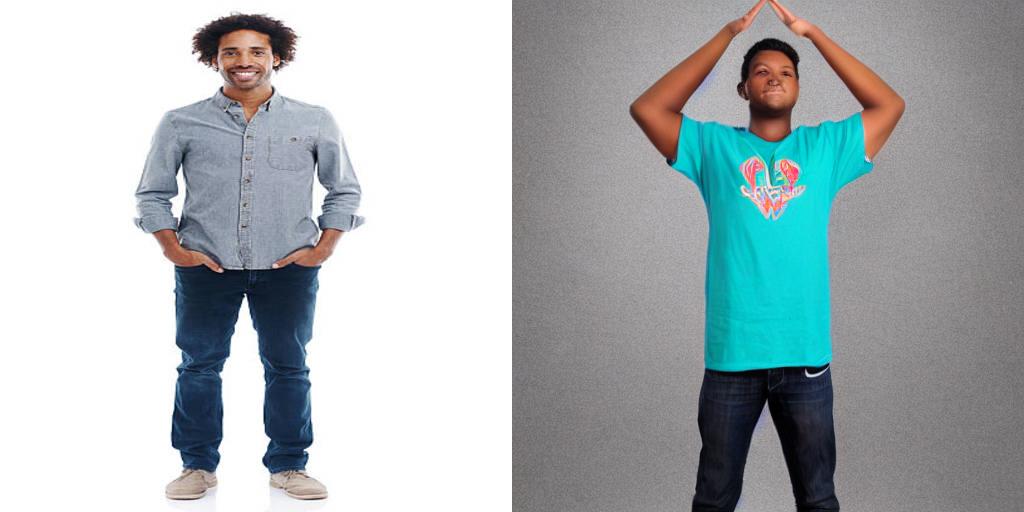

In [3]:
# [셀 3] 참조 사진을 준비하고 512x512 정사각형으로 맞춰 samples/ 에 저장
import os, gc
import torch
from PIL import Image, ImageOps
from diffusers import StableDiffusionPipeline
from diffusers.utils import load_image, make_image_grid

os.makedirs("samples", exist_ok=True)
SIZE = 512
USE_UPLOAD = False      # True로 바꾸면 내 사진을 올릴 수 있습니다

# 예시 사진 (Hugging Face 문서용 예시 사진, 서 있는 사람)
REF_URLS = [
    "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/person.png",
]

def prepare(img):
    """사진을 RGB로 바꾸고 가운데를 기준으로 512x512로 자릅니다."""
    return ImageOps.fit(ImageOps.exif_transpose(img).convert("RGB"), (SIZE, SIZE))

refs = []
if USE_UPLOAD:
    from google.colab import files
    uploaded = files.upload()          # 파일 선택 창
    for name in list(uploaded)[:2]:
        refs.append(prepare(Image.open(name)))

for url in REF_URLS:
    if len(refs) >= 2:
        break
    try:
        refs.append(prepare(load_image(url)))
        print("사용:", url)
    except Exception as e:
        print("건너뜀:", url, e)

# 사진이 2장이 안 되면, 포즈가 다른 참조 사진을 SD 1.5로 한 장 만들어 채웁니다
if len(refs) < 2:
    print("참조 사진이 부족해 SD 1.5로 두 팔을 든 사람 사진을 만듭니다.")
    t2i = StableDiffusionPipeline.from_pretrained(
        "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16
    ).to("cuda")
    g = torch.Generator("cuda").manual_seed(7)
    made = t2i(
        "full body photo of a young man standing and raising both arms straight up in the air, "
        "arms wide open, whole body visible from head to feet, plain white studio background",
        negative_prompt="cropped, close-up, lowres, blurry",
        num_inference_steps=30, generator=g,
    ).images[0]
    refs.append(prepare(made))
    del t2i; gc.collect(); torch.cuda.empty_cache()   # 메모리 비우기

for i, img in enumerate(refs, start=1):
    img.save(f"samples/ref_{i:02d}.png")
print(f"참조 사진 {len(refs)}장 준비 완료")
make_image_grid(refs, rows=1, cols=len(refs))

## 4. 포즈(뼈대) 추출
OpenPose가 사진에서 머리·어깨·팔꿈치·손목·골반·무릎·발목 위치를 찾아 **막대 인간 그림**으로 만듭니다.
이 그림이 다음 단계에서 "이 자세로 그려라"는 조건이 됩니다.

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/controlnet_aux/mediapipe_face/mediapipe_face_common.py:7: UserWarning: The module 'mediapipe' is not installed. The package will have limited functionality. Please install it using the command: pip install 'mediapipe'
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarni

body_pose_model.pth: reconstructing file:   0%|          |  0.00B /  209MB            

body_pose_model.pth: downloading bytes:           |  0.00B            

hand_pose_model.pth: reconstructing file:   0%|          |  0.00B /  147MB            

hand_pose_model.pth: downloading bytes:           |  0.00B            

facenet.pth: reconstructing file:   0%|          |  0.00B /  154MB            

facenet.pth: downloading bytes:           |  0.00B            

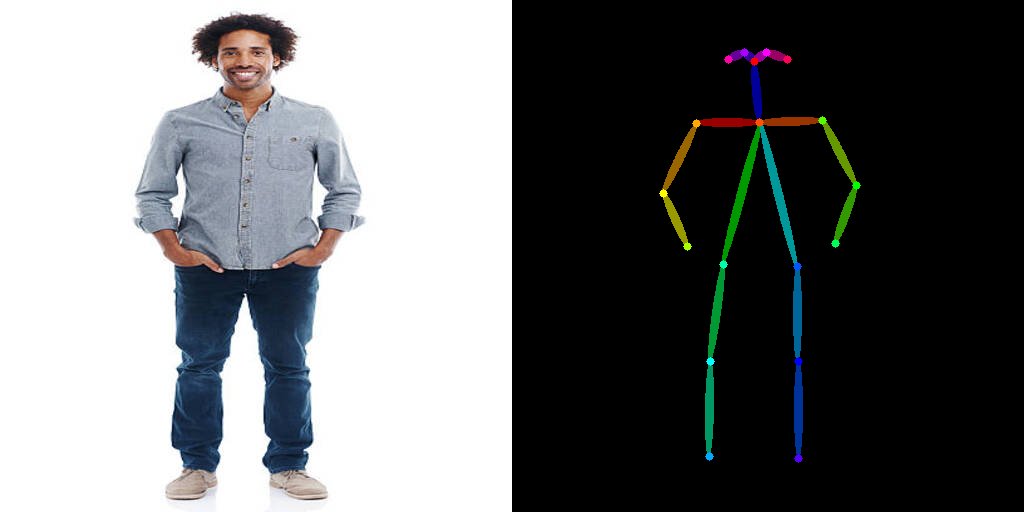

In [4]:
# [셀 4] 참조 사진에서 OpenPose 뼈대를 뽑아 samples/pose_XX.png 로 저장
from controlnet_aux import OpenposeDetector
from diffusers.utils import make_image_grid

openpose = OpenposeDetector.from_pretrained("lllyasviel/Annotators")

poses = []
for i, ref in enumerate(refs, start=1):
    pose = openpose(ref, detect_resolution=SIZE, image_resolution=SIZE)
    pose = pose.resize((SIZE, SIZE))
    pose.save(f"samples/pose_{i:02d}.png")
    poses.append(pose)

# 왼쪽: 참조 사진, 오른쪽: 뽑아낸 뼈대
make_image_grid([refs[0], poses[0]], rows=1, cols=2)

## 5. 모델 불러오기
- **ControlNet (OpenPose)**: 뼈대 그림을 읽어 자세를 고정하는 보조 신경망
- **Stable Diffusion 1.5**: 노이즈에서 그림을 만들어 내는 본체 모델

처음 실행하면 모델을 내려받느라 2~3분 걸립니다. 메모리를 아끼려고 float16(반정밀도)으로 불러옵니다.

In [5]:
# [셀 5] OpenPose ControlNet + Stable Diffusion 1.5 파이프라인 불러오기
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler

controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/control_v11p_sd15_openpose", torch_dtype=torch.float16
)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=controlnet,
    torch_dtype=torch.float16,
).to("cuda")

# 적은 스텝(20)으로도 품질이 나오는 스케줄러로 교체
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
print("모델 준비 완료")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/999 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

모델 준비 완료


## 6. 생성 함수 만들기
`generate(포즈, 프롬프트, 이름)` 한 줄로 이미지를 만들고 `samples/` 에 저장합니다.
- **SEED(시드)를 고정**해서, 결과가 달라지면 그건 프롬프트나 포즈를 바꿨기 때문이라고 말할 수 있게 합니다.
- 사용한 프롬프트·시드·포즈는 `log` 에 모아 두었다가 마지막에 `prompts.md` 로 저장합니다.

In [6]:
# [셀 6] 포즈 + 프롬프트 → 이미지 생성 함수 (시드 고정, 기록 남기기)
SEED = 42
STEPS = 20
NEGATIVE = "lowres, blurry, deformed hands, extra limbs"
log = []

def generate(pose, prompt, name, pose_name, seed=SEED):
    g = torch.Generator("cuda").manual_seed(seed)
    image = pipe(
        prompt,
        image=pose,
        negative_prompt=NEGATIVE,
        num_inference_steps=STEPS,
        controlnet_conditioning_scale=1.0,   # 포즈를 얼마나 강하게 따를지 (0~2)
        generator=g,
    ).images[0]
    image.save(f"samples/{name}.png")
    log.append({"file": f"{name}.png", "pose": pose_name, "prompt": prompt, "seed": seed})
    return image

## 7. 첫 번째 결과 만들기
포즈 1번으로 한 장 만들어 봅니다. 참조 사진과 **같은 자세**인지 확인하세요.

  0%|          | 0/20 [00:00<?, ?it/s]

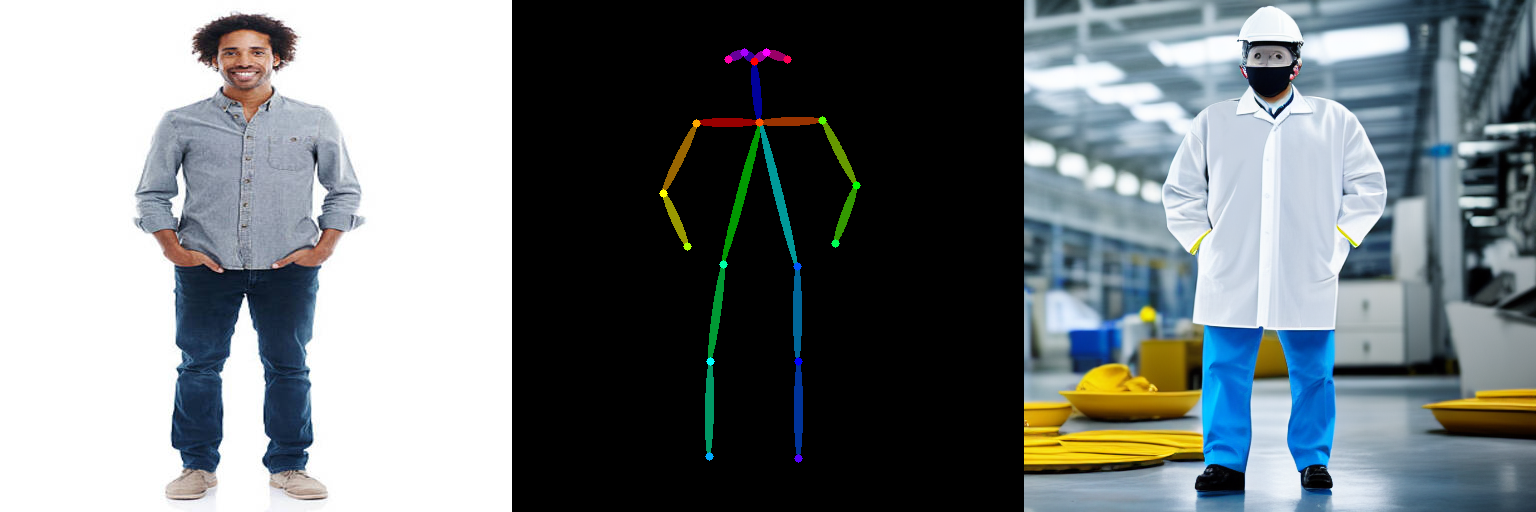

In [7]:
# [셀 7] 포즈 1 → output_01.png
prompt_1 = ("a factory worker in a white safety helmet and blue overalls, "
            "inside a bright manufacturing plant, photorealistic documentary photography")
out_1 = generate(poses[0], prompt_1, "output_01", "pose_01")

# 참조 사진 | 뼈대 | 결과
make_image_grid([refs[0], poses[0], out_1], rows=1, cols=3)

## 8. 실험 A — 같은 포즈, 다른 프롬프트
포즈는 그대로 두고 프롬프트(인물·장소·스타일)만 바꿉니다. **무엇이 바뀌고 무엇이 그대로인지** 보세요.

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

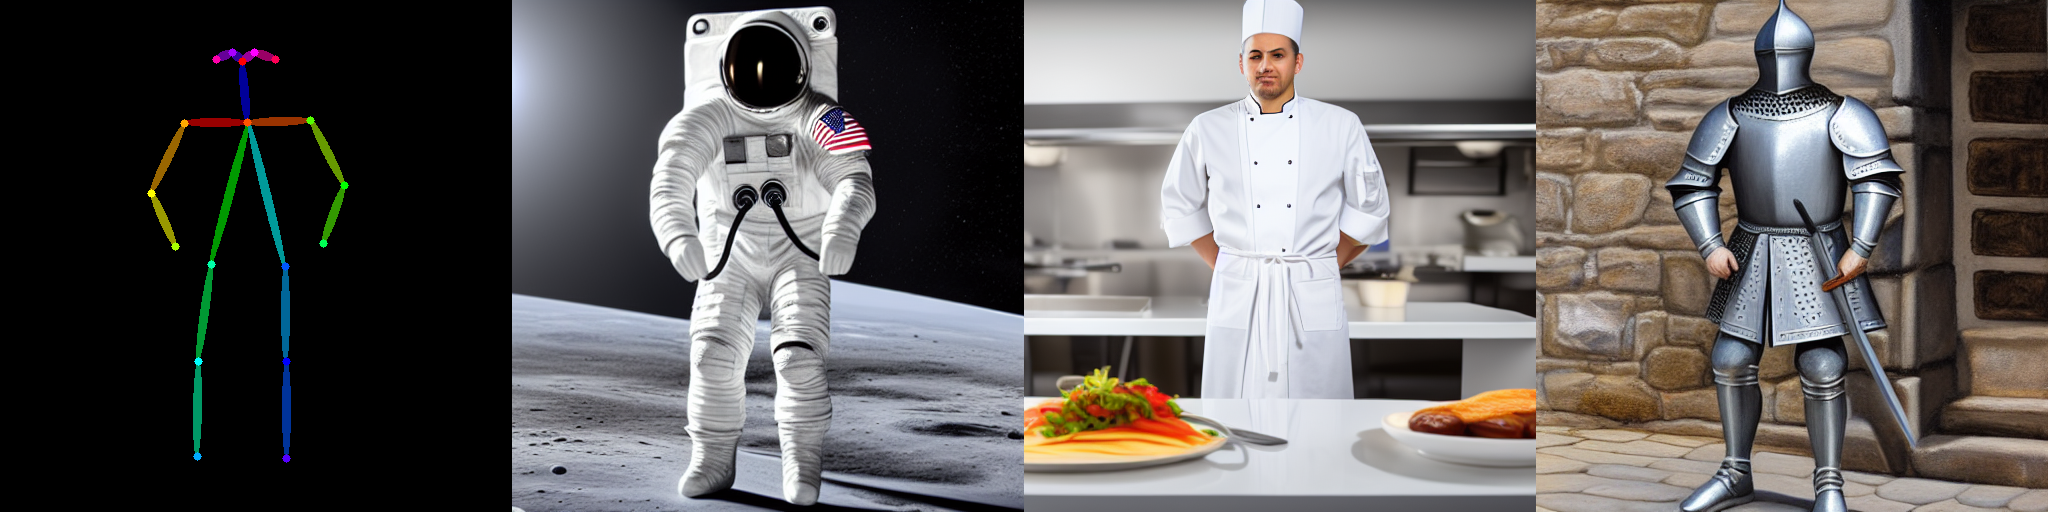

In [8]:
# [셀 8] 실험 A: 포즈 1 고정, 프롬프트 3가지
prompts_A = [
    "an astronaut in a white space suit on the surface of the moon, photorealistic",
    "a chef in a white uniform in a busy restaurant kitchen, warm lighting, photorealistic",
    "a knight in silver armor in a medieval castle courtyard, oil painting style",
]
outs_A = [generate(poses[0], p, f"expA_{i:02d}", "pose_01") for i, p in enumerate(prompts_A, start=1)]
make_image_grid([poses[0]] + outs_A, rows=1, cols=4)

## 9. 실험 B — 다른 포즈, 같은 프롬프트
프롬프트는 그대로 두고 포즈만 바꿉니다. 사진을 2장 올렸다면 포즈 2번 결과(`output_02.png`)도 여기서 만들어집니다.

  0%|          | 0/20 [00:00<?, ?it/s]

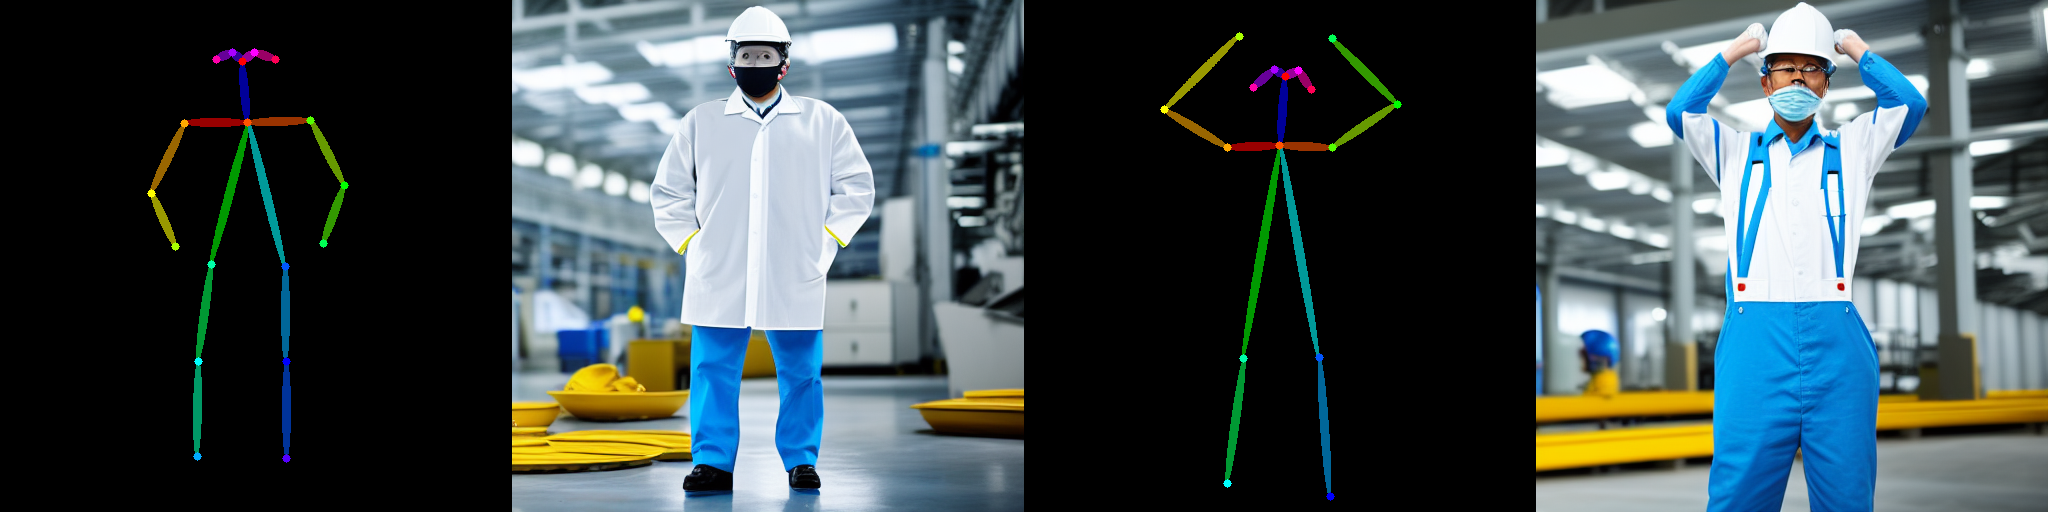

In [9]:
# [셀 9] 실험 B: 프롬프트 고정, 포즈 바꾸기
if len(poses) < 2:
    print("포즈가 1개뿐입니다. 셀 3에서 사진을 2장 올리면 실험 B를 할 수 있습니다.")
else:
    out_2 = generate(poses[1], prompt_1, "output_02", "pose_02")
    display(make_image_grid([poses[0], out_1, poses[1], out_2], rows=1, cols=4))

## 10. (선택) 포즈를 얼마나 세게 따를지 바꿔 보기
`controlnet_conditioning_scale` 값을 낮추면 자세가 느슨해지고, 높이면 뼈대에 더 딱 붙습니다.

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

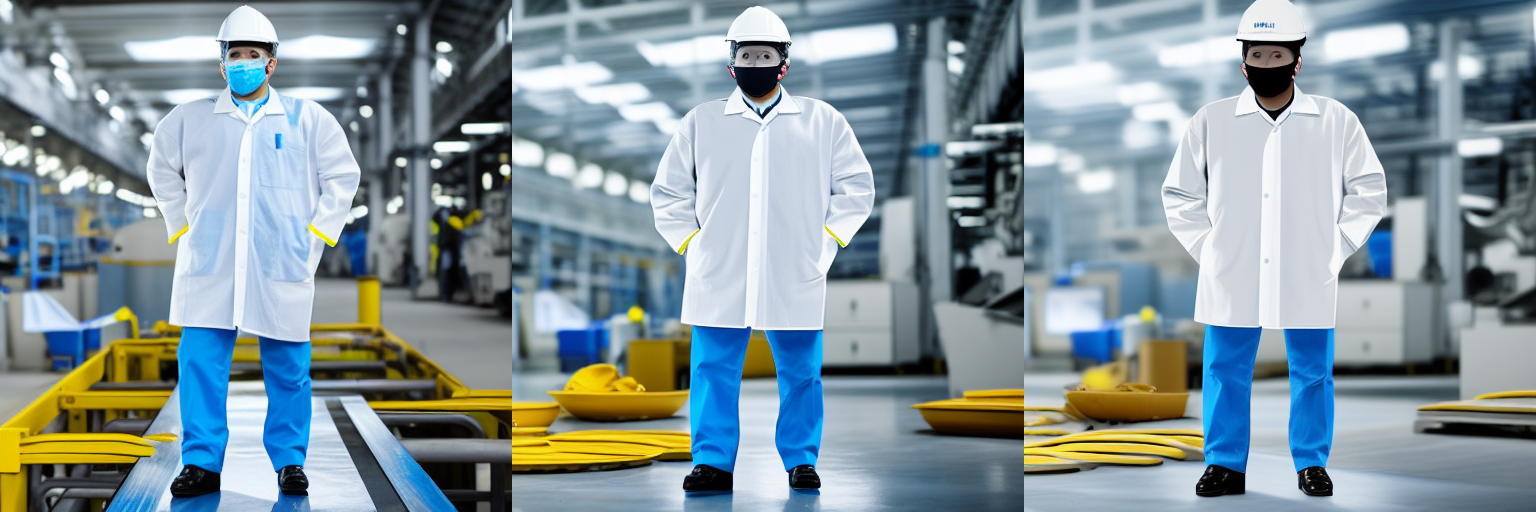

In [10]:
# [셀 10] 조건 세기 0.5 / 1.0 / 1.5 비교 (선택)
scales = [0.5, 1.0, 1.5]
outs_S = []
for s in scales:
    g = torch.Generator("cuda").manual_seed(SEED)
    img = pipe(prompt_1, image=poses[0], negative_prompt=NEGATIVE,
               num_inference_steps=STEPS, controlnet_conditioning_scale=s, generator=g).images[0]
    img.save(f"samples/scale_{s}.png")
    log.append({"file": f"scale_{s}.png", "pose": "pose_01", "prompt": prompt_1 + f"  (scale={s})", "seed": SEED})
    outs_S.append(img)
make_image_grid(outs_S, rows=1, cols=3)

## 11. 결과 저장하기
사용한 프롬프트를 `prompts.md` 로 저장하고, `samples/` 폴더와 함께 zip으로 묶어 내려받습니다. 이 파일들을 GitHub에 올리면 됩니다.

In [11]:
# [셀 11] prompts.md 자동 작성 + samples 폴더를 zip으로 내려받기
lines = ["# 테스트에 쓴 프롬프트", "",
         f"- 모델: Stable Diffusion 1.5 + ControlNet v1.1 OpenPose",
         f"- 시드: {SEED} / 스텝: {STEPS}",
         f"- 네거티브 프롬프트: `{NEGATIVE}`", "",
         "| 결과 파일 | 포즈 | 프롬프트 |", "|---|---|---|"]
for r in log:
    lines.append(f"| {r['file']} | {r['pose']} | {r['prompt']} |")
open("prompts.md", "w", encoding="utf-8").write("\n".join(lines))

import shutil
shutil.make_archive("pose_results", "zip", ".", "samples")
try:
    from google.colab import files
    files.download("pose_results.zip")
    files.download("prompts.md")
except Exception:
    print("Colab이 아니면 pose_results.zip, prompts.md 를 직접 가져가세요.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. 실험 기록

모든 실험은 시드 42, 스텝 20으로 고정했습니다. 그래서 결과가 달라졌다면 바꾼 조건(프롬프트 또는 포즈) 때문입니다.

### 실험 A — 같은 포즈, 다른 프롬프트
- 바꾼 것: 공장 작업자 → 우주비행사 → 요리사 → 기사(유화 스타일)
- 그대로 유지된 것: 똑바로 서서 정면을 보는 자세, 어깨너비로 벌린 다리, 몸 옆으로 내린 팔이 네 장 모두 같았습니다.
- 달라진 것: 옷(작업복 / 우주복 / 조리복 / 갑옷), 배경(공장 / 달 표면 / 주방 / 성 안뜰), 전체 분위기가 프롬프트대로 바뀌었습니다.
- 잘 안 된 점
  - 참조 사진은 손을 주머니에 넣은 자세인데, 주머니가 없는 우주복·갑옷에서는 손을 옆에 애매하게 두었습니다.
  - 프롬프트에 없던 물건이 생겼습니다. 기사는 칼을 쥐었고, 요리사 앞에는 음식 접시가 놓였습니다.
  - "oil painting style"이라고 적었지만 기사 그림은 거의 사진처럼 나왔습니다.

### 실험 B — 다른 포즈, 같은 프롬프트
- 바꾼 것: 포즈 1(손을 주머니에 넣고 선 자세) → 포즈 2(두 손을 머리 위로 올려 맞댄 자세)
- 자세를 잘 따라왔는가: 잘 따라왔습니다. 포즈 2에서 팔꿈치가 양옆으로 벌어지고 두 손이 머리 위로 올라간 모양이 그대로 나왔습니다.
- 무너진 부분
  - 두 손이 머리 위에서 맞닿는 대신 안전모를 붙잡는 모양으로 바뀌었고, 손가락은 뭉개졌습니다.
  - 프롬프트가 같은데도 옷이 바뀌었습니다(흰 가운 → 멜빵 작업복).
  - 두 결과 모두 프롬프트에 없던 마스크가 얼굴에 생겼습니다.

### 조건 세기 0.5 / 1.0 / 1.5 (controlnet_conditioning_scale)
- 0.5: 손을 주머니에 넣은 자세는 유지됐지만 배경이 컨베이어 라인으로 바뀌는 등 그림이 더 많이 달라졌습니다.
- 1.0과 1.5: 거의 같은 그림이었습니다. 1.5에서 몸이 조금 더 뻣뻣하게 정면을 봅니다.
- 이 정도로 단순한 자세는 1.0이면 충분했습니다.

### 정리
- 결과가 더 크게 달라진 쪽: **프롬프트를 바꿨을 때**입니다. 옷·배경·분위기가 통째로 바뀌었습니다. 포즈를 바꾸면 자세만 바뀌고 장면의 분위기는 거의 유지됐습니다.
- 이 도구의 한계
  - 손과 손가락이 자주 뭉개집니다.
  - 프롬프트에 적지 않은 것(마스크, 칼, 접시)은 모델이 마음대로 채웁니다. 교안의 "안 적은 것은 모델이 대신 정한다"와 같은 현상입니다.
  - SD 1.5라서 512×512 해상도가 기본이고, 사진처럼 선명하지는 않습니다.